**Author**: [Nna](https://github.com/andalive)

**Referensi**: </br>
- [Kaggle | SVM from Scratch](https://www.kaggle.com/code/fareselmenshawii/svm-from-scratch)
- [Github | MWalega/ml_algos_python/SVM.py](https://github.com/MWalega/ml_algos_python/blob/master/SVM.py)
- [Github | akash18tripathi/SVM-from-scratch-Constraints-analysis/SVM.ipynb](https://github.com/akash18tripathi/SVM-from-scratch-Constraints-analysis/blob/main/SVM.ipynb)
- [Youtube | Siddhardhan: Support Vector Machine Classifier from Scratch](https://youtube.com/playlist?list=PLfFghEzKVmjvzS4DILijsdQk27Ew7xIPu&feature=shar)

## 1. GENERAL CONCEPTS

---

### KONSEP KLASIFIKASI BINER

Klasifikasi biner dalam pembelajaran mesin merupakan algoritma *supervised learning* yang mengategorisasikan data pada dua kelas berbeda. Beberapa metode yang biasa diterapkan dalam proses klasifikasi biner dapat berupa:

1. K-Nearest Neighbors (KNN)
2. Decision trees
3. Random forest
4. **Support Vector Machine** (SVM), dll.

Metrik evaluasi paling umum dalam masalah klasifikasi biner adalah **akurasi**.

### KONSEP SVM

*Support Vector Machine* (SVM) merupakan algoritma *supervised machine learning* yang mengklasifikasikan data dengan mencari garis optimal yang merupakan jarak terjauh antar klasifikasi data pada ruang dimensinya. Pada klasifikasi biner, SVM bertujuan menemukan batas pemisah (*decision boundary*) yang dapat memisahkan data ke dalam dua kelas.

Dalam klasifikasi biner, label kelas umumnya direpresentasikan menggunakan:
* Kelas positif: ($y_i=+1$)
* Kelas negatif: ($y_i=-1$)

![SVM Marigin](Lampiran/500px-SVM_margin.png)

**Kompoenen penting** dalam SVM meliputi:
1. **Hyperplane**: garis atau bidang yang memisahkan *data-points* dalam dua kelas.
2. **Support vector**: *data-points* yang berada dekat dengan *hyperplane*.

### MODEL MATEMATIS KLASIFIKASI SVM

**🟦 (1) Fungsi Objektif dan *Hyperplane***

Klasifikasi SVM ditentukan oleh sebuah garis linier--*hyperplane* yang membagai dua kelas (target) dari dataset, dinyatakan sebagai:

</br>

$$
f(x) = w^Tx + b
$$

</br>

dimana: </br>
* $w$: vektor bobot (*weight*)
* $b$: parameter bias yang menentukan posisi hyperplane
* $x$: vektor fitur dari suatu data

Prediksi kelas ditentukan berdasarkan tanda dari fungsi keputusan:

$$
\hat{y}=
\begin{cases}
+1, & f(x)>0\\
-1, & f(x)<0
\end{cases}
$$

Apabila ($f(x)=0$), data berada tepat pada batas pemisah (*decision boundary*).

Dengan demikian, persamaan hyperplane dapat dituliskan sebagai:

$$
\boxed{
w^Tx+b=0
}
$$


**🟦 (2) Margin dan Support Vectors**

SVM tidak hanya berusaha memisahkan kedua kelas, tetapi juga memaksimalkan jarak antara batas pemisah dengan data terdekat dari masing-masing kelas. Jarak tersebut dikenal sebagai *margin*.

Eliminasi dua batas margin pada SVM dituliskan sebagai berikut.

\begin{array}{rcl}
w^Tx_1 + b &= &+1 \\
w^Tx_2 + b &= &-1 \\
\end{array}

Berdasarkan hasil eliminiasi kedua persamaan sebelumnya, dapat diproses lebih lanjut menjadi:

\begin{align}
w^T(x_1 - x_2) &= 2 \\
\frac{w^T}{||w||} (x_1-x_2) &= \frac{2}{||w||} \\
(1)(x_1-x_2) &= \frac{2}{||w||} \\
(x_1-x_2) &= \frac{2}{||w||}
\end{align}

Hasil tersebut menentukan lebar kedua batas margin:

$$
\boxed{M=\frac{2}{\|w\|}}
$$

Data yang berada paling dekat dengan batas pemisah dan berperan dalam menentukan posisi margin disebut **support vectors**.


**🟦 (3) Hard-Margin SVM**

Pendekatan **hard-margin** ini mengharuskan seluruh data berada pada sisi yang benar dan tidak melanggar batas margin. Memaksimalkan margin ekuivalen dengan meminimalkan kuadrat norm dari vektor bobot, sehingga optimasi Hard-Margin SVM dirumuskan sebagai:

$$
\max_{w,b}\frac{2}{\|w\|}
\equiv
\boxed{
\min_{w,b}\frac{1}{2}\|w\|^2
}
$$

dengan *constraint*:

$$
y_i(w^Tx_i+b)\geq1,
\quad i=1,\ldots,n
$$


**🟦 (4) Soft-Margin SVM**

Pendekatan *soft-margin* memberikan toleransi terhadap data yang melanggar batas margin dengan memperkenalkan variabel tambahan yang disebut *slack variable* ($\xi_i$). *Constraint* klasifikasi kemudian diubah menjadi:

$$
y_i(w^Tx_i+b)\geq1-\xi_i
$$

dengan ketentuan:

$$
\xi_i\geq0
$$

Nilai $\xi_i$ menunjukkan tingkat pelanggaran margin pada suatu data:

- $\xi_i=0$: data berada di luar atau tepat pada batas margin.
- $0<\xi_i<1$: data berada di dalam margin, tetapi masih diklasifikasikan dengan benar.
- $\xi_i=1$: data berada tepat pada batas pemisah.
- $\xi_i>1$: data berada pada sisi yang salah dari batas pemisah sehingga mengalami salah klasifikasi.

Fungsi objektif Soft-Margin SVM dengan parameter penalti $C$ dirumuskan sebagai:

$$
\boxed{
\min_{w,b,\xi}
\frac{1}{2}\|w\|^2+
C\sum_{i=1}^{n}\xi_i
}
$$

Nilai $C$ yang lebih besar memberikan penalti lebih tinggi, sedangkan nilai $C$ lebih kecil memberikan toleransi lebih besar terhadap pelanggaran.

**🟦 (5) Hinge Loss**

Dalam implementasi SVM, tingkat pelanggaran margin dapat dihitung menggunakan fungsi *Hinge Loss*. Nilai *Hinge Loss* bergantung pada posisi data terhadap margin

Berdasarkan kendala Soft-Margin, diperoleh bentuk minimum dari slack variable ($\xi_i\geq0$) sebagai fungsi *Hinge Loss*:

\begin{align}
y_i(w^Tx_i+b) &\geq 1-\xi_i \\
\xi_i &\geq 1-y_i(w^Tx_i+b) \\
\xi_i &= \max{(0, 1-y_i(w^Tx_i+b))}
\end{align}

Fungsi Hinge Loss dapat dituliskan sebagai:

$$
\boxed{
L_i=\max(0,1-y_if(x_i))
}
$$

Dengan $f(x_i)=w^Tx_i+b$.

**🟦 (6) Regularisasi**

Soft-Margin SVM dapat dinyatakan menggunakan fungsi objektif berbasis Hinge Loss:

$$
\boxed{
J(w,b)=
\frac{\lambda}{2}\|w\|^2+
\frac{1}{n}\sum_{i=1}^{n}
\max(0,1-y_i(w^Tx_i+b))
}
$$

Terdapat 2 komponen utama:

1. **Regularisasi:** $\frac{\lambda}{2}\|w\|^2$, berfungsi mengendalikan besarnya bobot model agar tidak terlalu besar.
2. **Hinge Loss:** mengukur tingkat pelanggaran margin pada data pelatihan.

**🟦 (7) Optimasi Menggunakan Gradient Descent**

Untuk memperoleh parameter \(w\) dan \(b\) yang meminimalkan fungsi objektif, proses optimasi dapat dilakukan menggunakan metode *Gradient Descent*.

Secara umum, pembaruan parameter dilakukan menggunakan:

$$
w_{\text{baru}}=w_{\text{lama}}-\eta\nabla_wJ
$$

$$
b_{\text{baru}}=b_{\text{lama}}-\eta\nabla_bJ
$$

dimana:

- $\eta$: *learning rate* yang menentukan besar langkah pembaruan parameter.
- $\nabla_wJ$: gradien fungsi objektif terhadap bobot.
- $\nabla_bJ$: gradien fungsi objektif terhadap bias.

Untuk fungsi objektif pada bagian sebelumnya, gradien ditentukan berdasarkan dua kondisi.

| Kondisi | Keterangn | Gradien |
| --- | --- | --- |
| $y_i(w^Tx_i+b)\geq1$ | Data berada di luar atau tepat pada margin | $\nabla_wJ=\lambda w$ </br> $\nabla_bJ=0$|
| $y_i(w^Tx_i+b)<1$ | Data berada di dalam margin atau salah diklasifikasikan | $\nabla_wJ=\lambda w-y_ix_i$ </br> $\nabla_bJ=-y_i$ |

Gradien tersebut digunakan untuk memperbarui bobot dan bias secara iteratif hingga proses optimasi mencapai kondisi konvergen atau memenuhi kriteria penghentian yang telah ditentukan.


**🟦 (8) Prediksi Kelas**

Setelah proses pelatihan selesai, model menggunakan fungsi keputusan:

$$
f(x)=w^Tx+b
$$

untuk menentukan kelas dari data baru.

Prediksi kelas dilakukan menggunakan fungsi tanda (*sign function*):

$$
\boxed{
\hat{y}=\operatorname{sign}(w^Tx+b)
}
$$

Hasil prediksi kemudian dapat dikonversi kembali ke label kelas awal sesuai dengan representasi label pada dataset.


## 2. IMPLEMENTATION

---


## 01. Introduction

**Electricity Dataset (Elec2)** dikumpulkan dari Pasar Listrik New South Wales (NSW), Australia. Dataset ini digunakan untuk mempelajari perubahan harga listrik dan merupakan masalah binary classification.

**Informasi**:
- **45.312** sampel observasi
- 8 fitur + 1 target

| Kolom | Deskripsi |
| --- | ---|
| `date` | info tanggal dinormalisasi (7 May 1996 s.d. 5 Dec 1998) |
| `day` | hari dalam seminggu (1-7) |
| `period` | periode pengamatan (1-48) dinormalisasi dalam interval setengah jam selama 24 jam|
| `nswprice` | harga listrik NSW |
| `nswdemand` | permintaan listrik NSW |
| `vicprice` | harga listrik Victoria |
| `vicdemand` | permintaan listrik Victoria |
| `transfer` | transfer listrik antarwilayah NSW-Victoria |
| `class` | target harga naik (`UP`) atau turun (`DOWN`) |

**Sumber**: 

- [Max Halford](https://maxhalford.github.io/files/datasets/electricity.zip)
- [Kaggle](https://www.kaggle.com/datasets/yashsharan/the-elec2-dataset)

## 02. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# from plotly.subplots import make_subplots
# import plotly.graph_objects as go
# import plotly.express as px


## 03. Load Dataset

In [2]:
URL = "https://maxhalford.github.io/files/datasets/electricity.zip"

df = pd.read_csv(URL, compression="zip")
df.head()


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,UP
1,0.0,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,UP
2,0.0,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,UP
3,0.0,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,UP
4,0.0,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,DOWN


## 04. Exploratory Data Analysis

### 4.1. DATASET INFO + DIMENSION

In [3]:
df.info()

print("\nRaw data shape:", df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45312 entries, 0 to 45311
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       45312 non-null  float64
 1   day        45312 non-null  int64  
 2   period     45312 non-null  float64
 3   nswprice   45312 non-null  float64
 4   nswdemand  45312 non-null  float64
 5   vicprice   45312 non-null  float64
 6   vicdemand  45312 non-null  float64
 7   transfer   45312 non-null  float64
 8   class      45312 non-null  object 
dtypes: float64(7), int64(1), object(1)
memory usage: 3.1+ MB

Raw data shape: (45312, 9)


### 4.2. STATISTICAL SUMMARY

**🟩 (1) Numerical Features**

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
date,45312.0,0.499080,0.340308,0.0,0.031934,0.456329,0.880547,1.0
day,45312.0,4.003178,1.998695,1.0,2.000000,4.000000,6.000000,7.0
period,45312.0,0.500000,0.294756,0.0,0.250000,0.500000,0.750000,1.0
nswprice,45312.0,0.057868,0.039991,0.0,0.035127,0.048652,0.074336,1.0
nswdemand,45312.0,0.425418,0.163323,0.0,0.309134,0.443693,0.536001,1.0
vicprice,45312.0,0.003467,0.010213,0.0,0.002277,0.003467,0.003467,1.0
vicdemand,45312.0,0.422915,0.120965,0.0,0.372346,0.422915,0.469252,1.0
transfer,45312.0,0.500526,0.153373,0.0,0.414912,0.414912,0.605702,1.0


**🟩 (2) Categorical Features**

In [5]:
df.describe(include='object').T


,count,unique,top,freq
class,45312,2,DOWN,26075


### 4.3. TARGET VARIABLE DISTRIBUTION

In [6]:
target_distribution = pd.DataFrame({
    'Class_count': df['class'].value_counts().values,
    'Class_percentage': (df['class'].value_counts(normalize=True)*100).round(2).values
}, index=df['class'].value_counts().index)

target_distribution


,Class_count,Class_percentage
class,,
DOWN,26075,57.55
UP,19237,42.45


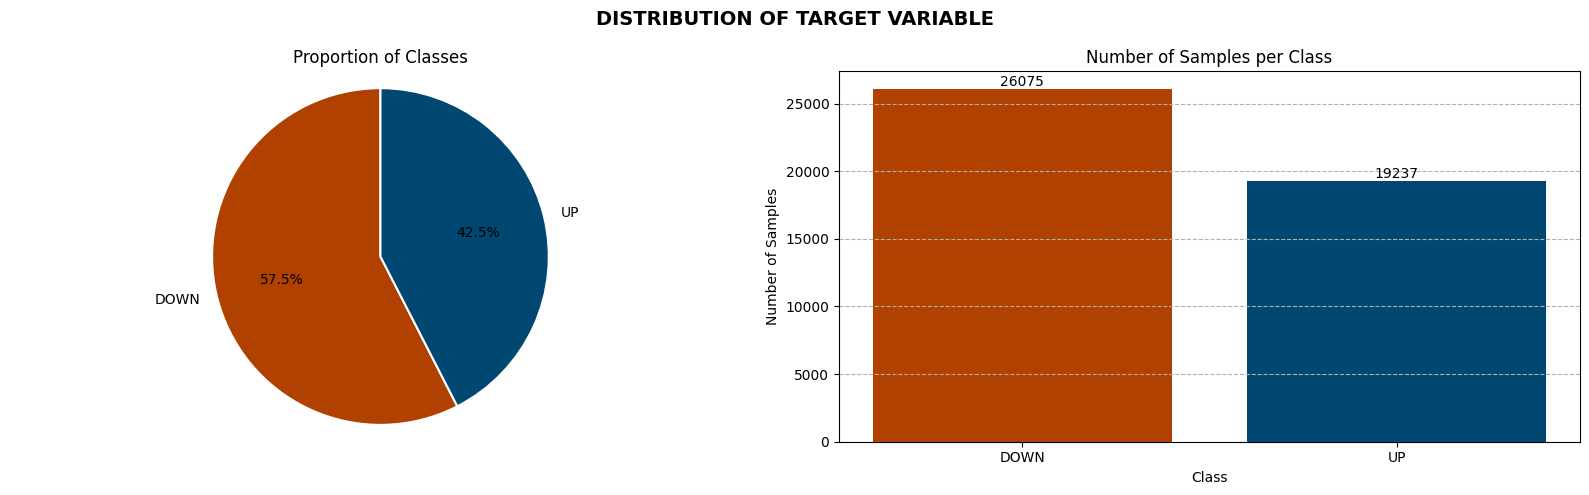

In [7]:
# Visualization of the target variable
class_colors = ["#B14100", "#004872"]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

ax[0].pie(target_distribution['Class_count'],
          labels=target_distribution.index,
          colors=class_colors,
          autopct='%1.1f%%',
          startangle=90,
          wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
ax[0].set_title('Proportion of Classes')
ax[0].axis('equal')

bars = ax[1].bar(target_distribution.index,
                 target_distribution['Class_count'],
                 color = class_colors)
ax[1].bar_label(bars)
ax[1].set_title('Number of Samples per Class')
ax[1].set_xlabel('Class')
ax[1].set_ylabel('Number of Samples')
ax[1].grid(axis='y', linestyle = '--')

fig.suptitle('DISTRIBUTION OF TARGET VARIABLE', fontsize=14, fontweight='bold')
fig.tight_layout()


📌 NOTE: 

Berdasarkan distribusi target variable, diketahui bahwa label kelas `DOWN` lebih banyak dibandingkan kelas `UP`.

### 4.4. MISSING + DUPLICATE VALUES

In [8]:
print("Number of missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())


Number of missing values in each column:
date         0
day          0
period       0
nswprice     0
nswdemand    0
vicprice     0
vicdemand    0
transfer     0
class        0
dtype: int64

Number of duplicate rows: 0


### 4.5. STATISTICAL ANALYSIS

In [9]:
cat_features = df.select_dtypes(include='object').columns.tolist()
num_features = df.select_dtypes(include='number').columns.tolist()

print("Categorical features:", cat_features)
print("Total fitur kategorikal:", len(cat_features))
print("\nNumerical features:", num_features)
print("Total fitur numerikal:", len(num_features))


Categorical features: ['class']
Total fitur kategorikal: 1

Numerical features: ['date', 'day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer']
Total fitur numerikal: 8


**🟩 (1) Univariate Analysis**

In [ ]:
num_colors = "#CA3025"
n_cols = 3
n_rows = (len(cat_features) + len(num_features) + n_cols - 1) // n_cols

fig, ax = plt.subplots(n_rows, n_cols, figsize=(16, 3*n_rows))
ax = ax.flatten()

# Data kategorikal
for i, col in enumerate(cat_features):
    sns.countplot(data=df, 
                  x=col, 
                  palette=class_colors, hue='class',
                  ax=ax[i])
    
    ax[i].set_title(f'Count of {col}')
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('Count')
    ax[i].grid(axis='y', linestyle = '--', alpha = 0.5)

# Data numerik
for i, col in enumerate(num_features):
    sns.histplot(data=df, 
                 x=col,
                 bins=30,
                 kde=True, 
                 color=num_colors,
                 ax=ax[i+len(cat_features)])
    
    ax[i+len(cat_features)].set_title(f'Distribution of {col}')
    ax[i+len(cat_features)].set_xlabel(col)
    ax[i+len(cat_features)].set_ylabel('Count')
    ax[i+len(cat_features)].grid(axis='y', linestyle = '--', alpha = 0.5)

# Remove empty subplots
for j in range(i+len(cat_features)+1, len(ax)):
    fig.delaxes(ax[j])

fig.suptitle('UNIVARIATE ANALYSIS - FEATURE DISTRIBUTION', fontsize=14, fontweight='bold')
fig.tight_layout()


📌 NOTE:

- `date`: terdiri dari tiga cluster sempit di **~0**, **~0,45**, dan **~0,9** dengan **celah kosong di antaranya**, artinya date bukan skala waktu linear.
- `nswprice`: sangat miring ke kanan. Hampir semua nilai ada di 0–0,15, dengan lonjakan harga yang ekstrem sampai 1,0.
- `nswdemand`: kira-kira unimodal dengan bahu di sekitar 0,2, kemungkinan cerminan pola siang-malam. Distribusinya sehat.
- `vicprice`: hampir semua baris ada di satu bin dekat 0. Sumbu y sampai 150 ribu adalah artefak KDE yang terlalu runcing (jumlah baris total hanya ~45 ribu).
- `vicdemand` dan `transfer`: masing-masing punya satu lonjakan tajam di ~0,42 yang berisi hampir 19 ribu baris (~40% data).

**🟩 (2) Bivariate Analysis**

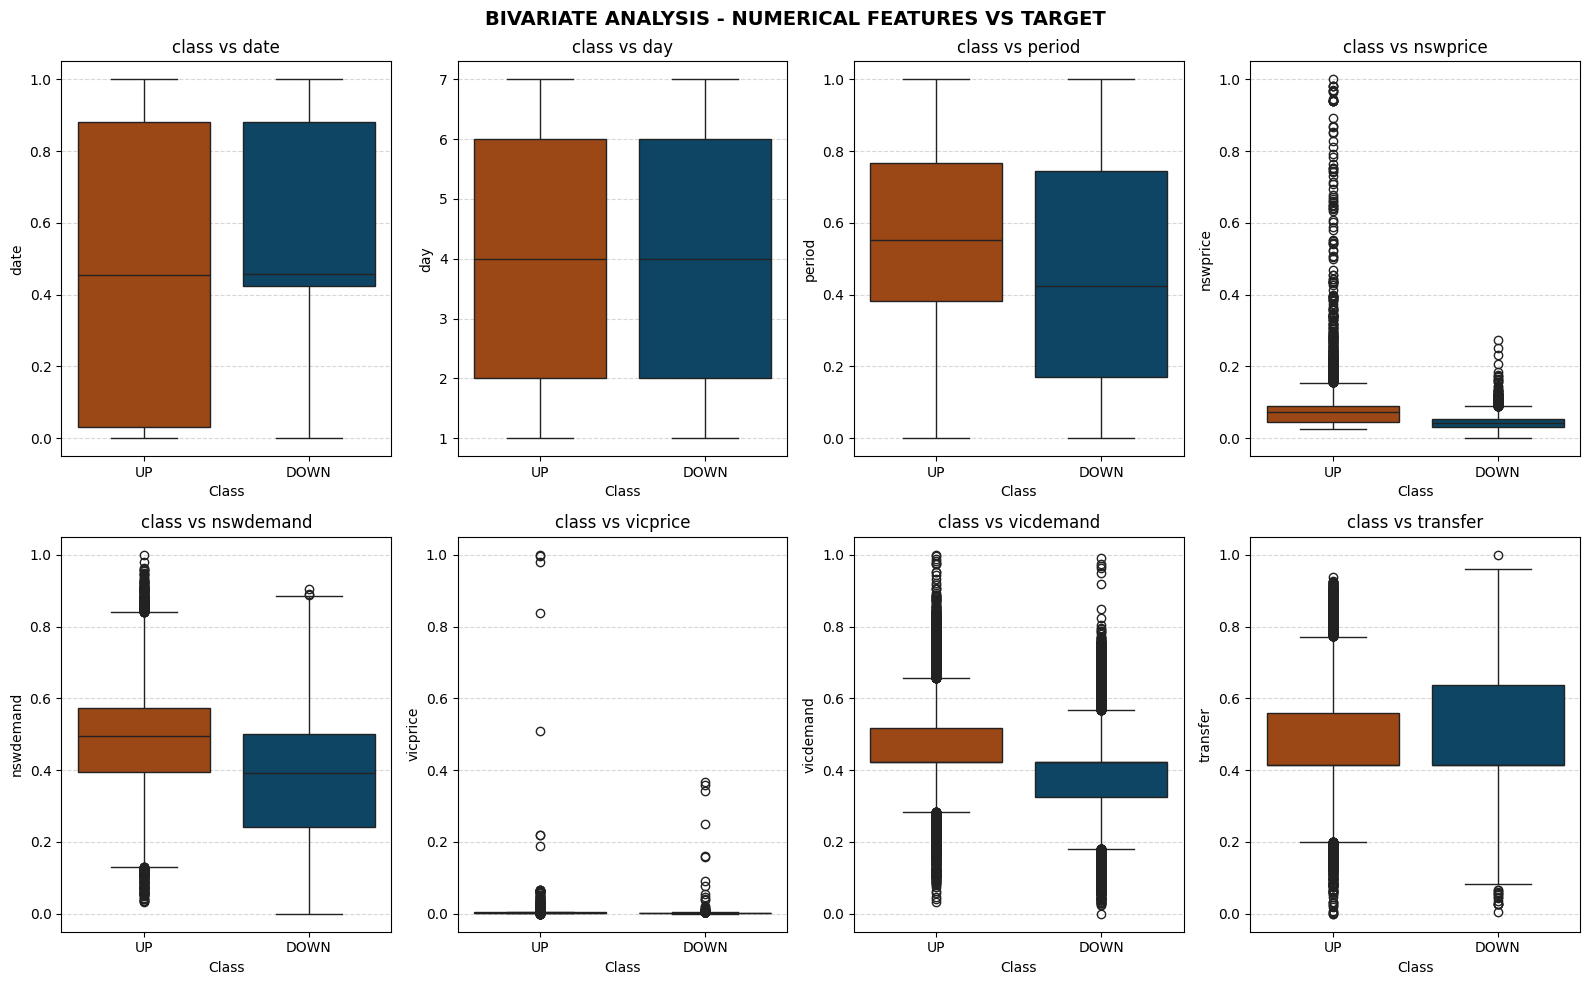

In [ ]:
ncols = 4
nrows = (len(num_features) + ncols - 1) // ncols

fig, ax = plt.subplots(nrows, ncols,figsize=(16, 5 * nrows))
ax = ax.flatten()

for i, col in enumerate(num_features):
    sns.boxplot(data=df,
                x='class', y=col,
                palette=class_colors, hue='class',
                legend=False,
                ax=ax[i])

    ax[i].set_title(f'class vs {col}')
    ax[i].set_xlabel('Class')
    ax[i].set_ylabel(col)
    ax[i].grid(axis='y', linestyle='--', alpha=0.5)

for i in range(len(num_features), len(ax)):
    fig.delaxes(ax[i])

fig.suptitle('BIVARIATE ANALYSIS - NUMERICAL FEATURES VS TARGET', fontsize=14, fontweight='bold')
fig.tight_layout()


📌 NOTE:

- `nswdemand` dan `vicdemand`: median UP lebih tinggi, sejalan dengan logika bahwa permintaan tinggi mendorong harga naik.

**🟩 (3) Correlation Analysis**

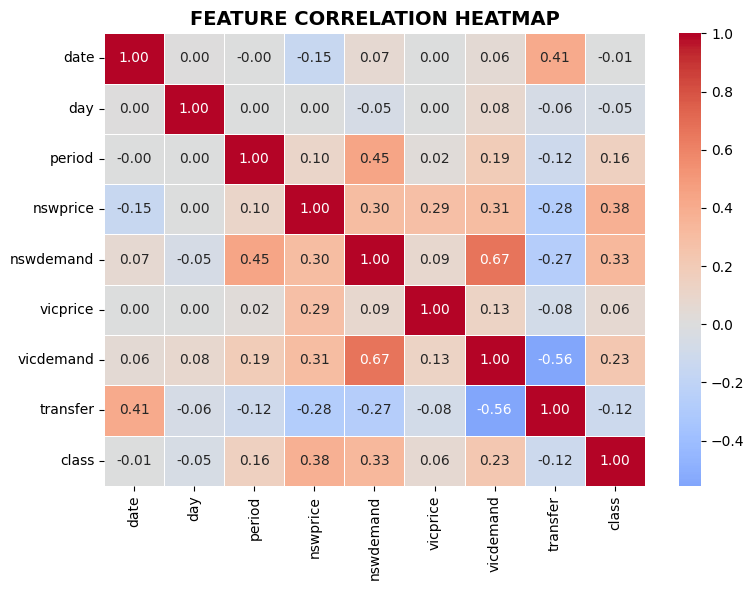

In [ ]:
df_corr = df.copy()
df_corr['class'] = df_corr['class'].map({'UP': 1, 'DOWN': 0})

corr_matrix = df_corr.corr()
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(corr_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            center=0,
            linewidths=0.5,
            ax=ax)

ax.set_title('FEATURE CORRELATION HEATMAP', fontsize=14, fontweight='bold')
fig.tight_layout()


📌 NOTE:

Korelasi sedang hingga cukup kuat ($corr > 0,4$ atau $corr < -0,4$) antar fitur berdasarkan heatmap di atas, di antaranya:

- `vicdemand` - `nswdemand` (+0,67)
- `nswdemand` - `period` (+0,45)
- `transfer` - `date` (+0,41)
- `transfer` - `vicdemand` (-0.56)

`date` dan `period` adalah variabel yang bersifat siklik/klaster, jadi korelasi Pearson dengan keduanya kurang bermakna.

### 4.6. TEMPORAL ANALYSIS

In [ ]:
time_cols = ['date', 'day', 'period']

display(df[time_cols].describe())

for col in time_cols:
    print(f"{col}:")
    print("Unique values:", df[col].nunique())
    print("Min:", df[col].min())
    print("Max:", df[col].max())
    print()


,date,day,period
count,45312.000000,45312.000000,45312.000000
mean,0.499080,4.003178,0.500000
std,0.340308,1.998695,0.294756
min,0.000000,1.000000,0.000000
25%,0.031934,2.000000,0.250000
50%,0.456329,4.000000,0.500000
75%,0.880547,6.000000,0.750000
max,1.000000,7.000000,1.000000


date:
Unique values: 933
Min: 0.0
Max: 1.0

day:
Unique values: 7
Min: 1
Max: 7

period:
Unique values: 48
Min: 0.0
Max: 1.0



📌 NOTE:

`date` dan `period` memang telah dalam bentuk normalisasi (0-1), lalu dapat dilihat bahwa nilai unik `periode` berjumlah 48 yang mana sesuai dengan informasi dataset bahwa periode pengamtan per hari-nya tiap 48x per 30 menit. Lalu, representasi hari ditetapkan dengan angka 1-7.


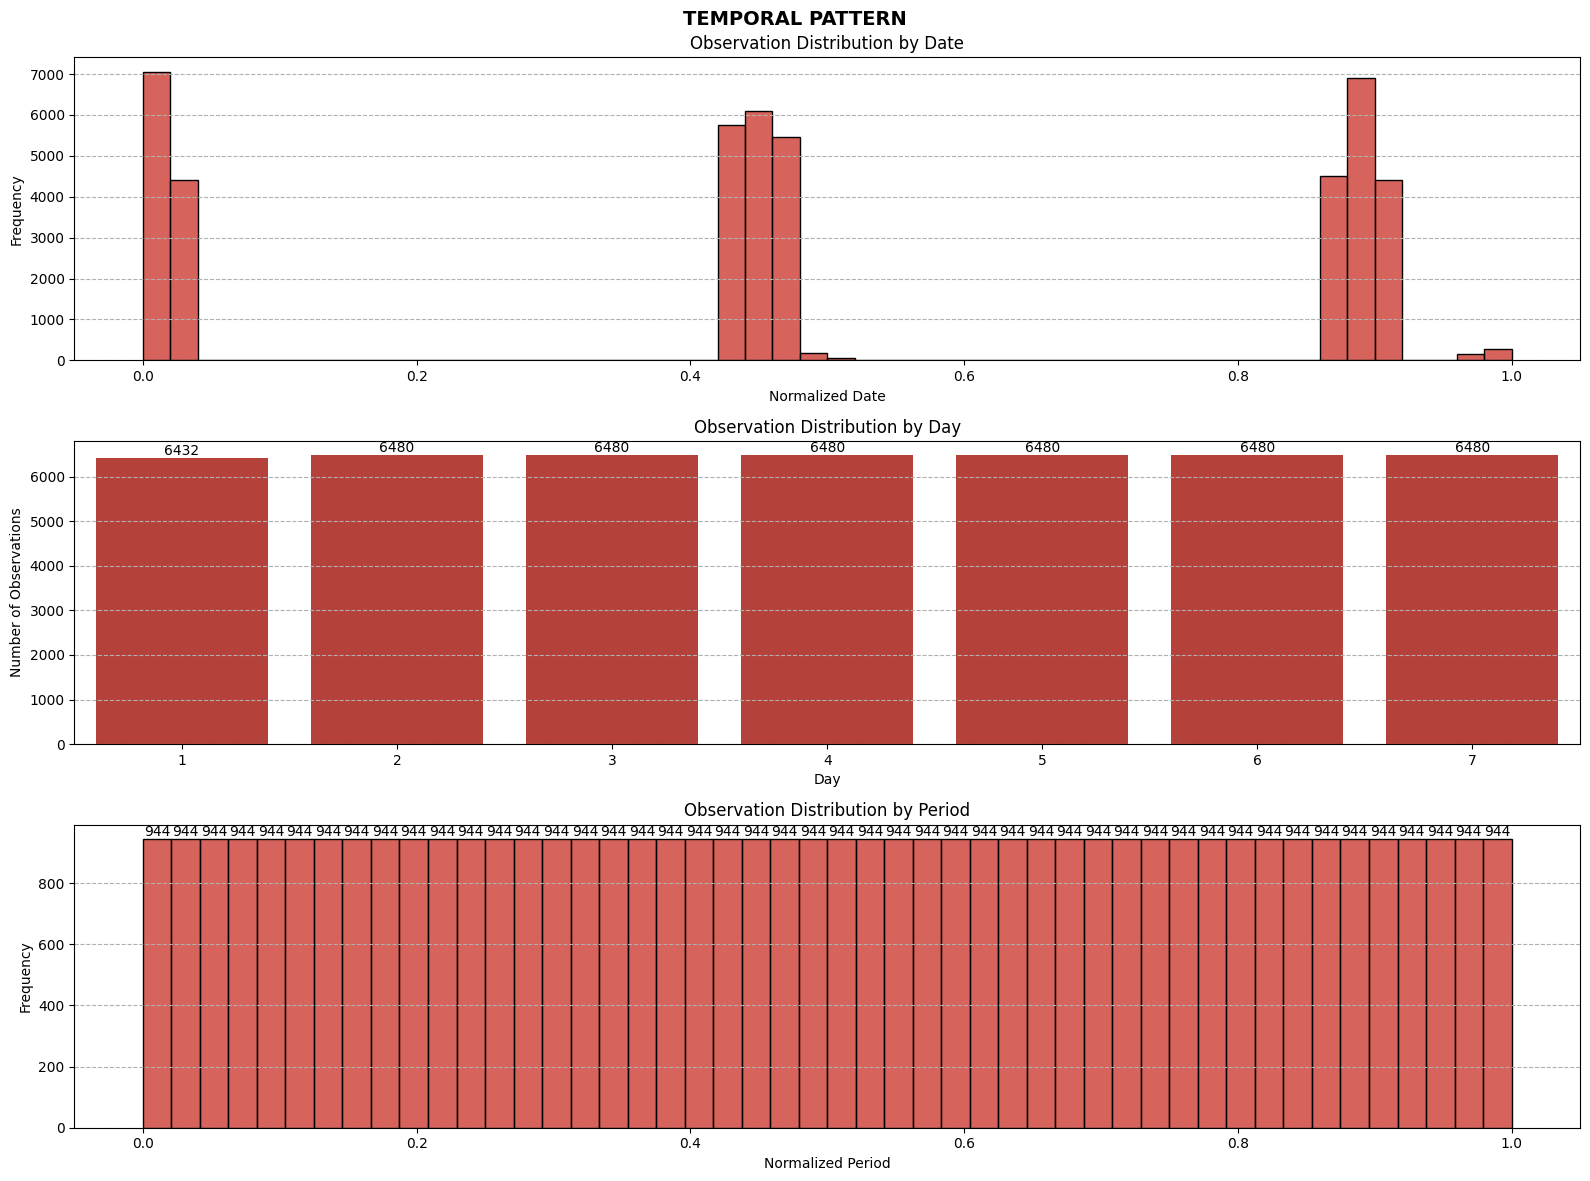

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(16, 12))

sns.histplot(data=df, 
             x='date', bins=50, 
             color=num_colors, ax=ax[0])
ax[0].set_title('Observation Distribution by Date')
ax[0].set_xlabel('Normalized Date')
ax[0].set_ylabel('Frequency')
ax[0].grid(axis='y', linestyle = '--')

sns.countplot(data=df,
              x='day',order=sorted(df['day'].unique()),
              color=num_colors,ax=ax[1])
ax[1].bar_label(ax[1].containers[0])
ax[1].set_title('Observation Distribution by Day')
ax[1].set_xlabel('Day')
ax[1].set_ylabel('Number of Observations')
ax[1].grid(axis='y', linestyle = '--')

sns.histplot(data=df, 
             x='period', bins=48, 
             color=num_colors, ax=ax[2])
ax[2].bar_label(ax[2].containers[0])
ax[2].set_title('Observation Distribution by Period')
ax[2].set_xlabel('Normalized Period')
ax[2].set_ylabel('Frequency')
ax[2].grid(axis='y', linestyle = '--')

fig.suptitle('TEMPORAL PATTERN', fontsize=14, fontweight='bold')
fig.tight_layout()


📌 NOTE:

- `period`: 48 batang seragam di 944 $\left( \frac{45.312\text{ data}}{48\text{ data pengukuran/hari}} = 944\text{ hari} \right)$. Jumlah total hari adalah 944.
- `day`: data pengukuran hari 1 lebih rendah (6432) dibandingkan hari lainnya (6480).
- `date`: ada 3 cluster, merepresentasikan data pengukuran dalam tahun 1996, 1997, dan 1998.

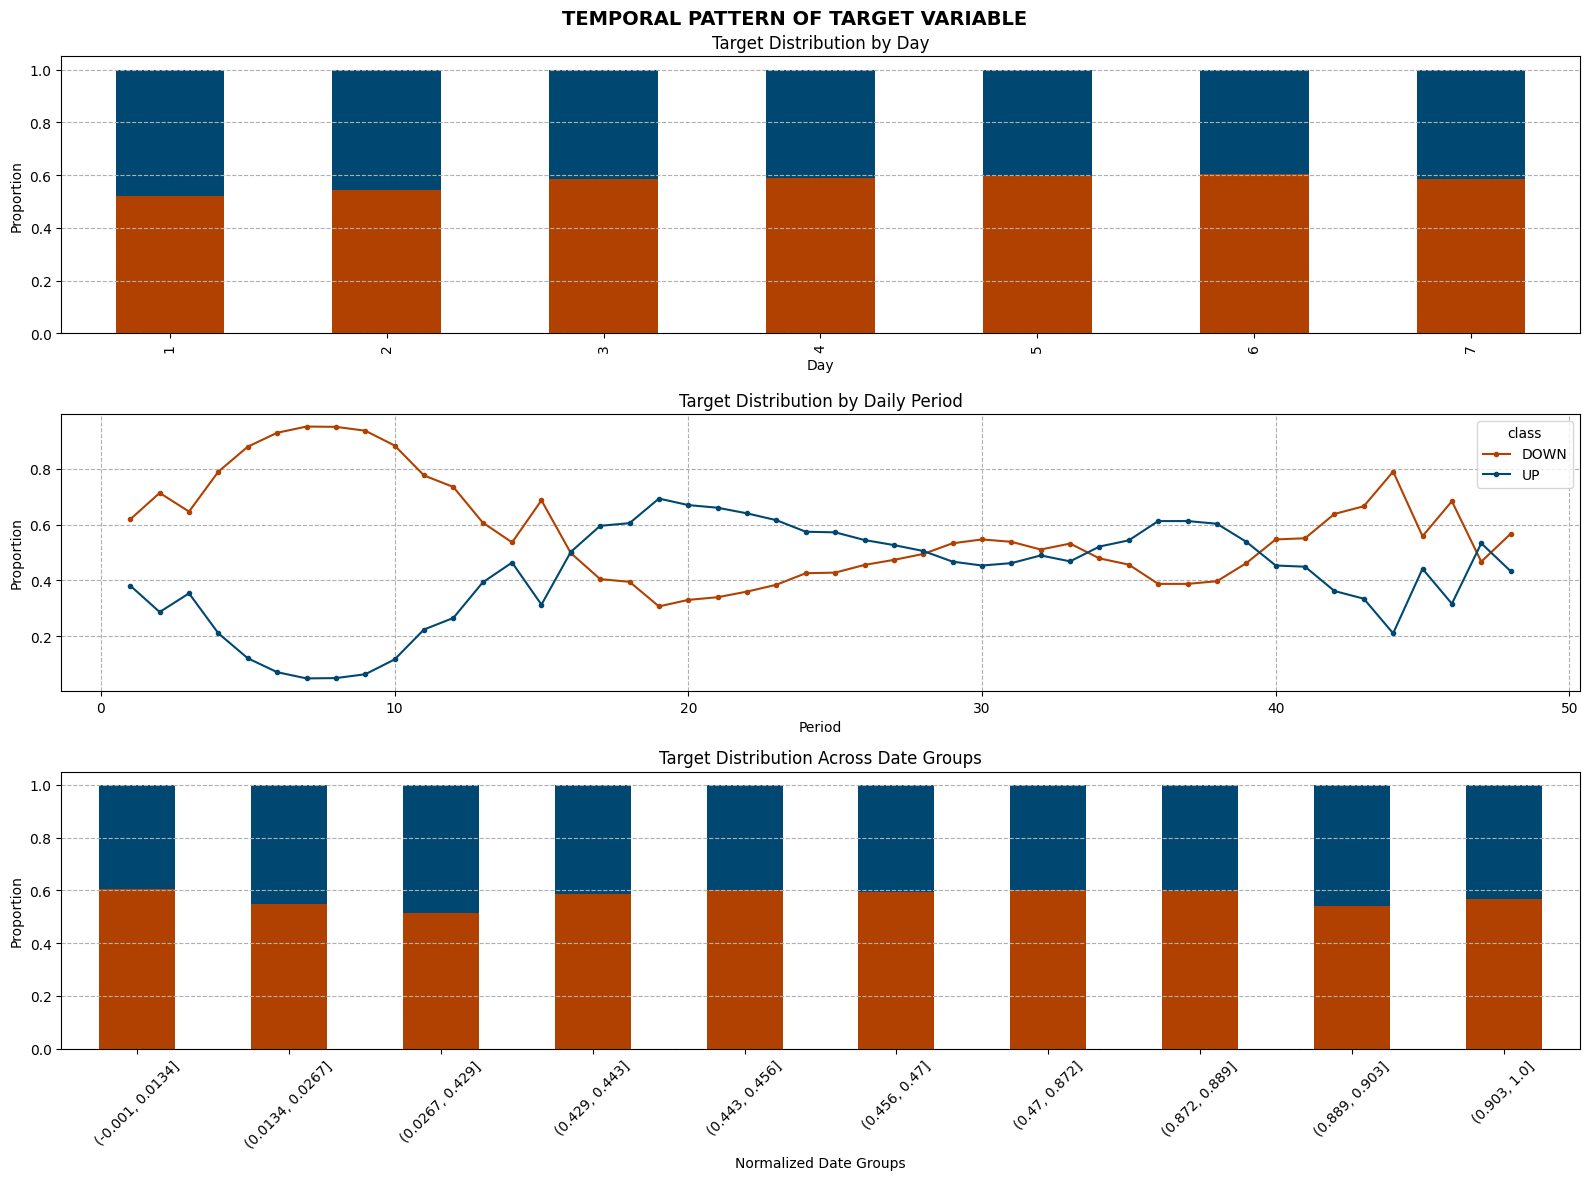

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(16, 12))

# 1. Target Distribution by Day
day_target = pd.crosstab(df['day'],
                         df['class'],
                         normalize='index')
day_target.plot(kind='bar', stacked=True, legend=False,
                color=class_colors, ax=ax[0])

ax[0].set_title('Target Distribution by Day')
ax[0].set_xlabel('Day')
ax[0].set_ylabel('Proportion')
ax[0].grid(axis='y', linestyle = '--')

# 2. Target Distribution by Daily Period
df_temporal = df.copy()
df_temporal['period_group'] = (df_temporal['period'] * 47).round().astype(int) + 1

period_target = pd.crosstab(df_temporal['period_group'],
                            df_temporal['class'],
                            normalize='index')
period_target.plot(kind='line', marker='.', legend=True,
                   color=class_colors, ax=ax[1])

ax[1].set_title('Target Distribution by Daily Period')
ax[1].set_xlabel('Period')
ax[1].set_ylabel('Proportion')
ax[1].grid(linestyle = '--')

# 3. Target Distribution Across Date Groups
df_temporal['date_group'] = pd.qcut(df_temporal['date'], q=10, duplicates='drop')

date_target = pd.crosstab(df_temporal['date_group'],
                          df_temporal['class'],
                          normalize='index')
date_target.plot(kind='bar', stacked=True, legend=False,
                 color=class_colors, ax=ax[2])

ax[2].set_title('Target Distribution Across Date Groups')
ax[2].set_xlabel('Normalized Date Groups')
ax[2].set_ylabel('Proportion')
ax[2].tick_params(axis='x', rotation=45)
ax[2].grid(axis='y', linestyle = '--')

fig.suptitle('TEMPORAL PATTERN OF TARGET VARIABLE', fontsize=14, fontweight='bold')
fig.tight_layout()


## 05. Pre-Processing

### 5.1. FEATURE SELECTION + TARGET ENCODIG

In [ ]:
df_processed = df.copy()
df_processed.head()


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.0,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,UP
1,0.0,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,UP
2,0.0,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,UP
3,0.0,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,UP
4,0.0,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,DOWN


In [ ]:
X = df_processed.drop(columns=['date', 'day', 'period', 'class'])

y = df_processed['class'].map({
    'DOWN': -1,
    'UP': 1
})

display(pd.concat([X, y.rename('class')], axis=1).head())


,nswprice,nswdemand,vicprice,vicdemand,transfer,class
0,0.056443,0.439155,0.003467,0.422915,0.414912,1
1,0.051699,0.415055,0.003467,0.422915,0.414912,1
2,0.051489,0.385004,0.003467,0.422915,0.414912,1
3,0.045485,0.314639,0.003467,0.422915,0.414912,1
4,0.042482,0.251116,0.003467,0.422915,0.414912,-1


### 5.2. TRAIN-TEST SPLIT

In [ ]:
# 1. Random split
X_train_random, X_test_random, y_train_random, y_test_random = train_test_split(
    X, y, 
    test_size=0.2,
    shuffle=True,
    random_state=42, 
    stratify=y
)

# 2. Chronological split
split_idx = int(len(X) * 0.8)

X_train_chron = X.iloc[:split_idx]
y_train_chron = y.iloc[:split_idx]
X_test_chron = X.iloc[split_idx:]
y_test_chron = y.iloc[split_idx:]

split_summary = pd.DataFrame({
    'Random Train': [
        len(X_train_random),
        y_train_random.value_counts(normalize=True).get(-1, 0),
        y_train_random.value_counts(normalize=True).get(1, 0)
    ],
    'Random Test': [
        len(X_test_random),
        y_test_random.value_counts(normalize=True).get(-1, 0),
        y_test_random.value_counts(normalize=True).get(1, 0)
    ],
    'Chronological Train': [
        len(X_train_chron),
        y_train_chron.value_counts(normalize=True).get(-1, 0),
        y_train_chron.value_counts(normalize=True).get(1, 0)
    ],
    'Chronological Test': [
        len(X_test_chron),
        y_test_chron.value_counts(normalize=True).get(-1, 0),
        y_test_chron.value_counts(normalize=True).get(1, 0)
    ]
}, index=['Samples', 'DOWN (-1)', 'UP (+1)'])

display(split_summary)


,Random Train,Random Test,Chronological Train,Chronological Test
Samples,36249.000000,9063.000000,36249.000000,9063.000000
DOWN (-1),0.575464,0.575417,0.582113,0.548825
UP (+1),0.424536,0.424583,0.417887,0.451175


### 5.3. FEATURE SCALING

In [ ]:
# scaling from random split
scaler_random = StandardScaler()
X_train_random_scaled = scaler_random.fit_transform(X_train_random)
X_test_random_scaled = scaler_random.transform(X_test_random)

# scaling from chronological split
scaler_chron = StandardScaler()
X_train_chron_scaled = scaler_chron.fit_transform(X_train_chron)
X_test_chron_scaled = scaler_chron.transform(X_test_chron)


## 06. Implementasi SVM